Found 14624 files belonging to 11 classes.
Using 11700 files for training.
Found 14624 files belonging to 11 classes.
Using 2924 files for validation.

Classes detected:
['battery', 'biological', 'brown-glass', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Number of classes: 11

Class weights:
{0: 1.3903743315508021, 1: 1.3463751438434983, 2: 2.1444281524926687, 3: 0.24985585239285027, 4: 2.1020481494789793, 5: 1.7266824085005903, 6: 1.254288164665523, 7: 1.5437392795883362, 8: 0.6809451751833314, 9: 1.9130150425114454, 10: 1.729490022172949}


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 11)                  │          14,091 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,272,075 (8.67 MB)

 Trainable params: 14,091 (55.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Starting Stage 1: Training the classifier
Epoch 1/20


C:\Users\DELL\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


366/366 ━━━━━━━━━━━━━━━━━━━━ 0s 559ms/step - accuracy: 0.8113 - loss: 0.7852
Epoch 1: val_accuracy improved from None to 0.91895, saving model to trained_waste_model\best_stage1.keras

Epoch 1: finished saving model to trained_waste_model\best_stage1.keras
366/366 ━━━━━━━━━━━━━━━━━━━━ 260s 691ms/step - accuracy: 0.8113 - loss: 0.7852 - val_accuracy: 0.9189 - val_loss: 0.2700 - learning_rate: 0.0010
Epoch 2/20
366/366 ━━━━━━━━━━━━━━━━━━━━ 0s 556ms/step - accuracy: 0.9054 - loss: 0.3950
Epoch 2: val_accuracy improved from 0.91895 to 0.93741, saving model to trained_waste_model\best_stage1.keras

Epoch 2: finished saving model to trained_waste_model\best_stage1.keras
366/366 ━━━━━━━━━━━━━━━━━━━━ 249s 681ms/step - accuracy: 0.9054 - loss: 0.3950 - val_accuracy: 0.9374 - val_loss: 0.2056 - learning_rate: 0.0010
Epoch 3/20
366/366 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - accuracy: 0.9191 - loss: 0.3288
Epoch 3: val_accuracy improved from 0.93741 to 0.94494, saving model to trained_waste_model\be

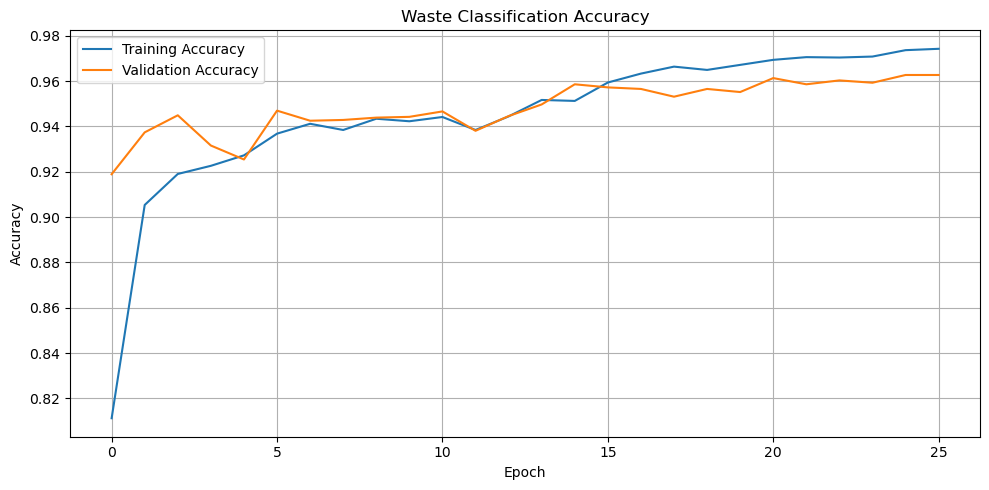

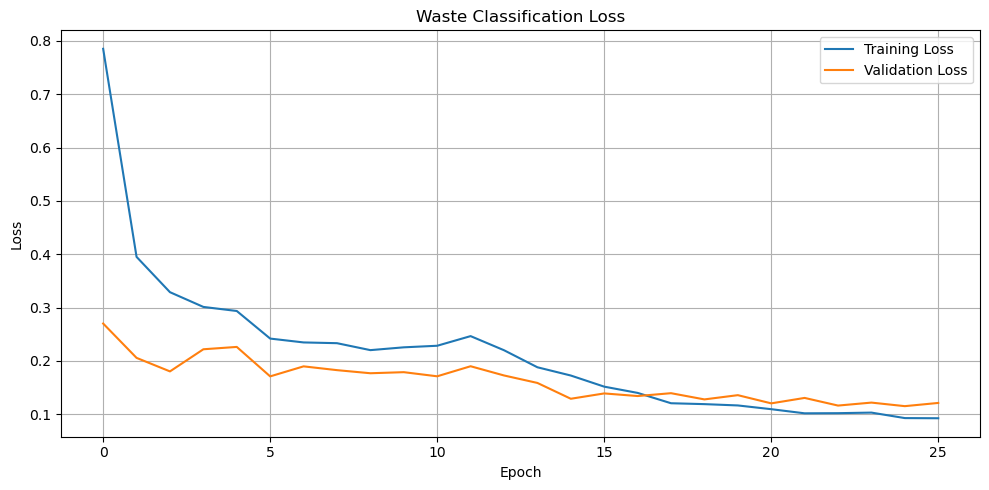


TRAINING COMPLETED SUCCESSFULLY!


In [1]:

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# --------------------------------------------------
# 1. SETTINGS
# --------------------------------------------------

# CHANGE THIS PATH to your main dataset folder.
# This folder must directly contain your class folders.
DATASET_PATH = r"C:\Users\DELL\OneDrive\Downloads\Vision_Based_Sorting_Project\garbage_classification"

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

INITIAL_EPOCHS = 20
FINE_TUNE_EPOCHS = 15

MODEL_DIR = "trained_waste_model"
os.makedirs(MODEL_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)

# --------------------------------------------------
# 2. LOAD TRAINING AND VALIDATION IMAGES
# --------------------------------------------------

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    r"C:\Users\DELL\OneDrive\Downloads\Vision_Based_Sorting_Project\garbage_classification",
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("\nClasses detected:")
print(class_names)
print("Number of classes:", num_classes)

if num_classes < 2:
    raise ValueError(
        "At least two class folders with images are required."
    )

# Save the class names in the same order as the model labels.
with open(
    os.path.join(MODEL_DIR, "class_names.json"),
    "w"
) as f:
    json.dump(class_names, f, indent=4)

# --------------------------------------------------
# 3. CALCULATE CLASS WEIGHTS
# --------------------------------------------------

all_labels = np.concatenate([
    labels.numpy() for images, labels in train_ds
])

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=all_labels
)

class_weights = {
    i: float(weights[i]) for i in range(num_classes)
}

print("\nClass weights:")
print(class_weights)

# --------------------------------------------------
# 4. IMPROVE DATA LOADING SPEED
# --------------------------------------------------

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# --------------------------------------------------
# 5. DATA AUGMENTATION
# --------------------------------------------------

augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="data_augmentation")

# --------------------------------------------------
# 6. LOAD PRETRAINED MOBILENETV2
# --------------------------------------------------

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers for the first training stage.
base_model.trainable = False

# --------------------------------------------------
# 7. BUILD THE CLASSIFICATION MODEL
# --------------------------------------------------

inputs = layers.Input(shape=(224, 224, 3))

x = augmentation(inputs)
x = preprocess_input(x)

# Keep pretrained BatchNormalization layers in inference mode.
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# --------------------------------------------------
# 8. CALLBACKS
# --------------------------------------------------

stage1_callbacks = [
    ModelCheckpoint(
        os.path.join(MODEL_DIR, "best_stage1.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# --------------------------------------------------
# 9. FIRST TRAINING STAGE
# --------------------------------------------------

print("\nStarting Stage 1: Training the classifier")

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=stage1_callbacks
)

# Load the best weights from Stage 1 before fine-tuning.
model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "best_stage1.keras")
)

# --------------------------------------------------
# 10. FINE-TUNE THE LAST PRETRAINED LAYERS
# --------------------------------------------------

print("\nStarting Stage 2: Fine-tuning MobileNetV2")

base_model = model.get_layer("mobilenetv2_1.00_224")
base_model.trainable = True

# Train only the last 30 layers of the pretrained model.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stability.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile after changing trainable layers.
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

stage2_callbacks = [
    ModelCheckpoint(
        os.path.join(MODEL_DIR, "best_stage2.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=stage2_callbacks
)

# --------------------------------------------------
# 11. LOAD THE BEST FINE-TUNED MODEL
# --------------------------------------------------

model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "best_stage2.keras")
)

# Save the final model.
final_model_path = os.path.join(
    MODEL_DIR, "waste_classifier.keras"
)

model.save(final_model_path)

print("\nFinal model saved at:")
print(os.path.abspath(final_model_path))

# --------------------------------------------------
# 12. VALIDATION ACCURACY
# --------------------------------------------------

val_loss, val_accuracy = model.evaluate(
    val_ds,
    verbose=1
)

print("\nValidation loss:", round(val_loss, 4))
print("Validation accuracy:", round(val_accuracy * 100, 2), "%")

# --------------------------------------------------
# 13. CLASSIFICATION REPORT
# --------------------------------------------------

true_labels = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

probabilities = model.predict(val_ds, verbose=1)
predicted_labels = np.argmax(probabilities, axis=1)

print("\nClassification report:")
print(classification_report(
    true_labels,
    predicted_labels,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(
    true_labels,
    predicted_labels,
    labels=list(range(num_classes))
))

# --------------------------------------------------
# 14. PLOT TRAINING ACCURACY AND LOSS
# --------------------------------------------------

train_accuracy = (
    history1.history["accuracy"]
    + history2.history["accuracy"]
)

validation_accuracy = (
    history1.history["val_accuracy"]
    + history2.history["val_accuracy"]
)

train_loss = (
    history1.history["loss"]
    + history2.history["loss"]
)

validation_loss = (
    history1.history["val_loss"]
    + history2.history["val_loss"]
)

plt.figure(figsize=(10, 5))
plt.plot(train_accuracy, label="Training Accuracy")
plt.plot(validation_accuracy, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Waste Classification Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(MODEL_DIR, "accuracy_graph.png")
)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(train_loss, label="Training Loss")
plt.plot(validation_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Waste Classification Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(MODEL_DIR, "loss_graph.png")
)
plt.show()

print("\nTRAINING COMPLETED SUCCESSFULLY!")


In [2]:

import os
import json

# Create a folder to store the model
SAVE_DIR = "trained_waste_model"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Save the complete trained model
model_path = os.path.join(
    SAVE_DIR,
    "waste_classifier.keras"
)

model.save(model_path)

print("Model saved successfully!")
print("Model location:", os.path.abspath(model_path))

# 2. Save class names in the correct order
with open(
    os.path.join(SAVE_DIR, "class_names.json"),
    "w"
) as file:
    json.dump(class_names, file, indent=4)

print("Class names saved successfully!")

# 3. Verify that the saved model can be loaded
loaded_model = tf.keras.models.load_model(model_path)

print("Saved model loaded successfully!")
print("Number of classes:", len(class_names))


Model saved successfully!
Model location: C:\Users\DELL\OneDrive\Downloads\Vision_Based_Sorting_Project\trained_waste_model\waste_classifier.keras
Class names saved successfully!
Saved model loaded successfully!
Number of classes: 11


In [4]:

import tensorflow as tf
import json
import os

SAVE_DIR = "trained_waste_model"

# Load the trained model
model = tf.keras.models.load_model(
    os.path.join(SAVE_DIR, "waste_classifier.keras")
)

# Load class labels
with open(
    os.path.join(SAVE_DIR, "class_names.json"),
    "r"
) as file:
    class_names = json.load(file)

print("Model loaded successfully!")
print("Classes:", class_names)


Model loaded successfully!
Classes: ['battery', 'biological', 'brown-glass', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
